# Demo so sánh tám phương pháp

Đọc dự báo đã khóa; không huấn luyện lại mô hình. Quan sát căn chỉnh, sai số từng tháng, metric, cải thiện baseline và giới hạn xếp hạng.

Chạy từ trên xuống bằng **Restart Kernel → Run All**, hoặc Shift+Enter từng cell. Thuật toán dùng lại từ `source/`; không sửa các CSV nghiên cứu đã có. Xem `notebooks/README.md` để cấu hình đường dẫn/kernel.

## Đường dẫn và môi trường
Kiểm tra các đường dẫn trước khi chạy. Các notebook độc lập: mặc định đọc clean/preparation đã lưu; không yêu cầu chạy notebook trước để có biến trong RAM.

In [4]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p/'source/preprocessing').is_dir() and (p/'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the repository root or notebooks directory.')
for folder in [PROJECT_ROOT, PROJECT_ROOT/'notebooks', PROJECT_ROOT/'source/preprocessing']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from demo_support import (configure, show_paths, demo_directory, save_table, save_json,
                          show_source, show_png, environment, compare_values, read_series, series_plot)
PATHS = configure(PROJECT_ROOT)
# Nếu cần, sửa PATHS.population_raw / history_raw / population_clean / history_clean / preparation tại đây.
show_paths(PATHS)
print('Python kernel:', sys.executable)


,setting,path,exists
0,project,D:\Phân tích kinh doanh_2627\GitHub\IS403.R14....,True
1,data_root,D:\Phân tích kinh doanh_2627,True
2,population_raw,D:\Phân tích kinh doanh_2627\archive\Electric_...,True
3,history_raw,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
4,population_clean,D:\Phân tích kinh doanh_2627\archive\EV_Popula...,True
5,history_clean,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
6,preparation,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True
7,output_root,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True


Python kernel: c:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe


In [5]:
OUT = demo_directory(PATHS, 'forecast_comparison')
print('Output demo:', OUT)
display(environment())


Output demo: D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\notebook_demo\forecast_comparison_20261116_041208_02215e19


,package,version,status
0,pandas,3.0.5,Đã tìm thấy
1,numpy,2.5.3,Đã tìm thấy
2,scipy,1.18.1,Đã tìm thấy
3,matplotlib,3.11.2,Đã tìm thấy
4,statsmodels,0.15.0,Đã tìm thấy
5,scikit-learn,1.9.1,Đã tìm thấy
6,xgboost,3.4.1,Đã tìm thấy
7,ipykernel,7.3.0,Đã tìm thấy


## Đọc chuỗi và dự báo đã khóa
Loader đối chiếu best metadata, actual, ngày, gốc, horizon và scale. SARIMA A/B tham khảo được loại khỏi bảng chính.

In [6]:
from source.forecasting.comparison import read_inputs, compare, selection_summary, verify_published_metrics
from source.forecasting.comparison_plots import draw, FIGURES
series = read_series(PATHS)
forecast_dir = PROJECT_ROOT/'results/forecasting'
aligned,choices,excluded = read_inputs(forecast_dir,series)
display(aligned[['model','config_id','date','origin','horizon','actual','pred']].head(12))
display(aligned.groupby(['model','config_id'],sort=False).size().rename('forecast_rows').to_frame())
display(pd.DataFrame(excluded))
assert len(aligned)==96


,model,config_id,date,origin,horizon,actual,pred
0,Naive,NAIVE,2022-12-31,2022-11-30,1,115665.0,112948.0
1,Naive,NAIVE,2023-01-31,2022-11-30,2,119377.0,112948.0
2,Naive,NAIVE,2023-02-28,2022-11-30,3,122322.0,112948.0
3,Naive,NAIVE,2023-03-31,2022-11-30,4,125478.0,112948.0
4,Naive,NAIVE,2023-04-30,2022-11-30,5,129728.0,112948.0
5,Naive,NAIVE,2023-05-31,2022-11-30,6,133975.0,112948.0
6,Naive,NAIVE,2023-06-30,2022-11-30,7,138353.0,112948.0
7,Naive,NAIVE,2023-07-31,2022-11-30,8,142537.0,112948.0
8,Naive,NAIVE,2023-08-31,2022-11-30,9,148730.0,112948.0
9,Naive,NAIVE,2023-09-30,2022-11-30,10,152690.0,112948.0


,,forecast_rows
model,config_id,
Naive,NAIVE,12
Drift,DRIFT,12
ARIMA,ARIMA_222,12
SARIMA,SARIMA_C,12
Ridge,RIDGE03,12
Random Forest,RF05,12
SVR,SVR02,12
XGBoost,XGB05,12


,model,config_id,reason,rows
0,SARIMA,SARIMA_A,candidate_reference,12
1,SARIMA,SARIMA_B,candidate_reference,12


## Xem cách tính và sai số theo tháng
Bias = actual−pred. Các metric được tính lại từ forecast, không chép bảng metric đầu vào.

In [7]:
from source.forecasting.metrics import calculate_metrics
show_source(calculate_metrics)
tables = compare(aligned)
tables['comparison_selection_summary.csv'] = selection_summary(forecast_dir,choices)
verify_published_metrics(forecast_dir,tables['comparison_metrics.csv'])
display(tables['comparison_errors.csv'][['model','date','actual','pred','error','absolute_error','smape_component']].head(12))


def calculate_metrics(actual,pred) -> dict[str,float]:
    actual,pred=np.asarray(actual,dtype=float),np.asarray(pred,dtype=float)
    if actual.ndim!=1 or pred.shape!=actual.shape or not actual.size:
        raise ValueError('Actual and prediction must be nonempty aligned one-dimensional vectors.')
    if not np.isfinite(actual).all() or not np.isfinite(pred).all():
        raise ValueError('Metrics require finite actuals and predictions.')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        error=actual-pred
        denominator=np.abs(actual)+np.abs(pred)
        terms=np.divide(200*np.abs(error),denominator,out=np.zeros_like(error),where=denominator!=0)
        return {'rmse':float(np.sqrt(np.mean(error**2))),'mae':float(np.mean(np.abs(error))),
                'smape':float(np.mean(terms)),'bias':float(np.mean(error))}

,model,date,actual,pred,error,absolute_error,smape_component
0,Naive,2022-12-31,115665.0,112948.0,2717.0,2717.0,2.376943
1,Naive,2023-01-31,119377.0,112948.0,6429.0,6429.0,5.534488
2,Naive,2023-02-28,122322.0,112948.0,9374.0,9374.0,7.968717
3,Naive,2023-03-31,125478.0,112948.0,12530.0,12530.0,10.510599
4,Naive,2023-04-30,129728.0,112948.0,16780.0,16780.0,13.829138
5,Naive,2023-05-31,133975.0,112948.0,21027.0,21027.0,17.031220
6,Naive,2023-06-30,138353.0,112948.0,25405.0,25405.0,20.218781
7,Naive,2023-07-31,142537.0,112948.0,29589.0,29589.0,23.163004
8,Naive,2023-08-31,148730.0,112948.0,35782.0,35782.0,27.348115
9,Naive,2023-09-30,152690.0,112948.0,39742.0,39742.0,29.921924


## Bảng xếp hạng và mức cải thiện baseline
Rank chính theo RMSE; MAE/sMAPE có thể xếp khác. Phần trăm giảm sai số không phải tăng lợi nhuận.

In [8]:
display(tables['comparison_metrics.csv'][['rank_rmse','model','rmse','mae','smape','bias',
                                         'rmse_improvement_vs_naive_pct','rmse_improvement_vs_drift_pct']])
display(tables['comparison_selection_summary.csv'])
print('Không so trực tiếp AIC của ARIMA với RMSE validation của các họ khác.')


,rank_rmse,model,rmse,mae,smape,bias,rmse_improvement_vs_naive_pct,rmse_improvement_vs_drift_pct
0,1,SARIMA,2354.900778,1771.095823,1.217804,1326.434189,91.638302,87.343693
1,2,ARIMA,2730.715887,2094.023345,1.446599,1268.546047,90.303871,85.323892
2,3,XGBoost,5064.830985,4154.766382,2.904539,4154.766382,82.015979,72.779296
3,4,Random Forest,5243.320964,4242.907515,2.959396,4242.907515,81.382203,71.820010
4,5,Ridge,5325.824073,4123.900879,2.851233,4123.900879,81.089254,71.376600
5,6,SVR,6020.980986,4814.062233,3.357829,4814.062233,78.620915,67.640511
6,7,Drift,18606.539282,15712.292857,11.655778,15712.292857,33.932564,0.000000
7,8,Naive,28162.950452,24176.500000,18.733318,24176.500000,0.000000,-51.360498


,model,config_id,train_end,train_months,selection_metric,selection_value,cv_folds,n_supervised,wald_inference_caution,selection_rule
0,ARIMA,ARIMA_222,2022-11-30,71,train_AIC,1052.003587,0,<NA>,True,lowest train AIC among converged finite candid...
1,SARIMA,SARIMA_C,2022-11-30,71,mean_validation_RMSE,2342.296305,3,<NA>,False,lowest mean full-precision RMSE over three tra...
2,Ridge,RIDGE03,2022-11-30,71,mean_validation_RMSE,815.793703,3,64,<NA>,"Within 1% of minimum mean validation RMSE, pre..."
3,Random Forest,RF05,2022-11-30,71,mean_validation_RMSE,814.141508,3,64,<NA>,"Within 1% of minimum mean validation RMSE, pre..."
4,SVR,SVR02,2022-11-30,71,mean_validation_RMSE,789.786364,3,64,<NA>,Minimum mean validation RMSE; exact ties use c...
5,XGBoost,XGB05,2022-11-30,71,mean_validation_RMSE,766.476139,3,64,<NA>,"Within 1% of minimum mean validation RMSE, pre..."


Không so trực tiếp AIC của ARIMA với RMSE validation của các họ khác.


## Khoảng dự báo và prefix tích lũy
Coverage 12/12 không chứng minh hiệu chuẩn dài hạn. Cumulative metric là một cửa sổ lồng nhau, không là nhiều gốc độc lập.

In [9]:
display(tables['comparison_interval_summary.csv'])
display(tables['comparison_cumulative_metrics.csv'].query("model == 'SARIMA'"))


,model,config_id,n_test,nominal_level,covered_months,observed_coverage,mean_width
0,ARIMA,ARIMA_222,12,0.95,12,1.0,21572.699316
1,SARIMA,SARIMA_C,12,0.95,12,1.0,17580.090696


,model,config_id,through_date,through_horizon,rmse,mae,smape,bias
36,SARIMA,SARIMA_C,2022-12-31,1,450.802070,450.802070,0.388990,-450.802070
37,SARIMA,SARIMA_C,2023-01-31,2,408.792073,406.370239,0.345860,-406.370239
38,SARIMA,SARIMA_C,2023-02-28,3,485.780682,474.690794,0.396749,-474.690794
39,SARIMA,SARIMA_C,2023-03-31,4,566.006906,545.343651,0.447991,-545.343651
40,SARIMA,SARIMA_C,2023-04-30,5,551.040862,533.593961,0.433270,-533.593961
41,SARIMA,SARIMA_C,2023-05-31,6,546.869666,532.247850,0.426562,-357.075418
42,SARIMA,SARIMA_C,2023-06-30,7,741.085301,660.755407,0.514235,-101.521680
43,SARIMA,SARIMA_C,2023-07-31,8,873.124099,765.840627,0.582324,98.848176
44,SARIMA,SARIMA_C,2023-08-31,9,1509.970017,1102.696252,0.804991,509.814073
45,SARIMA,SARIMA_C,2023-09-30,10,2031.876180,1448.114272,1.027453,914.520311


## Vẽ lại hình từ bảng vừa tính
Các hình do source tạo mới trong OUT.

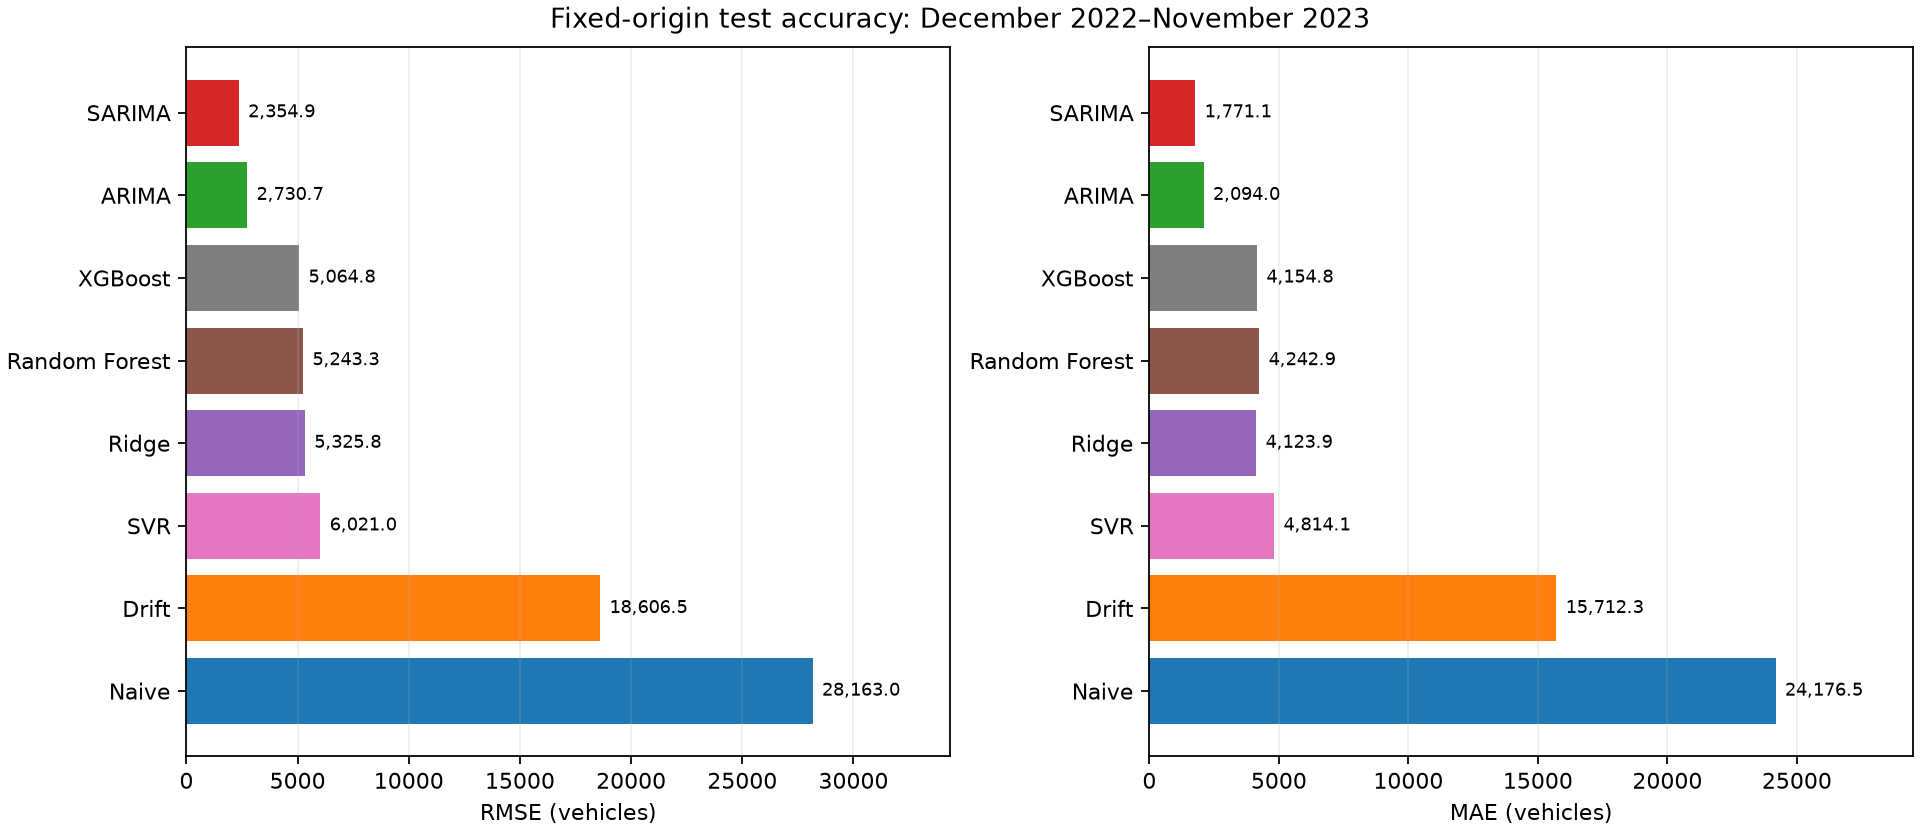

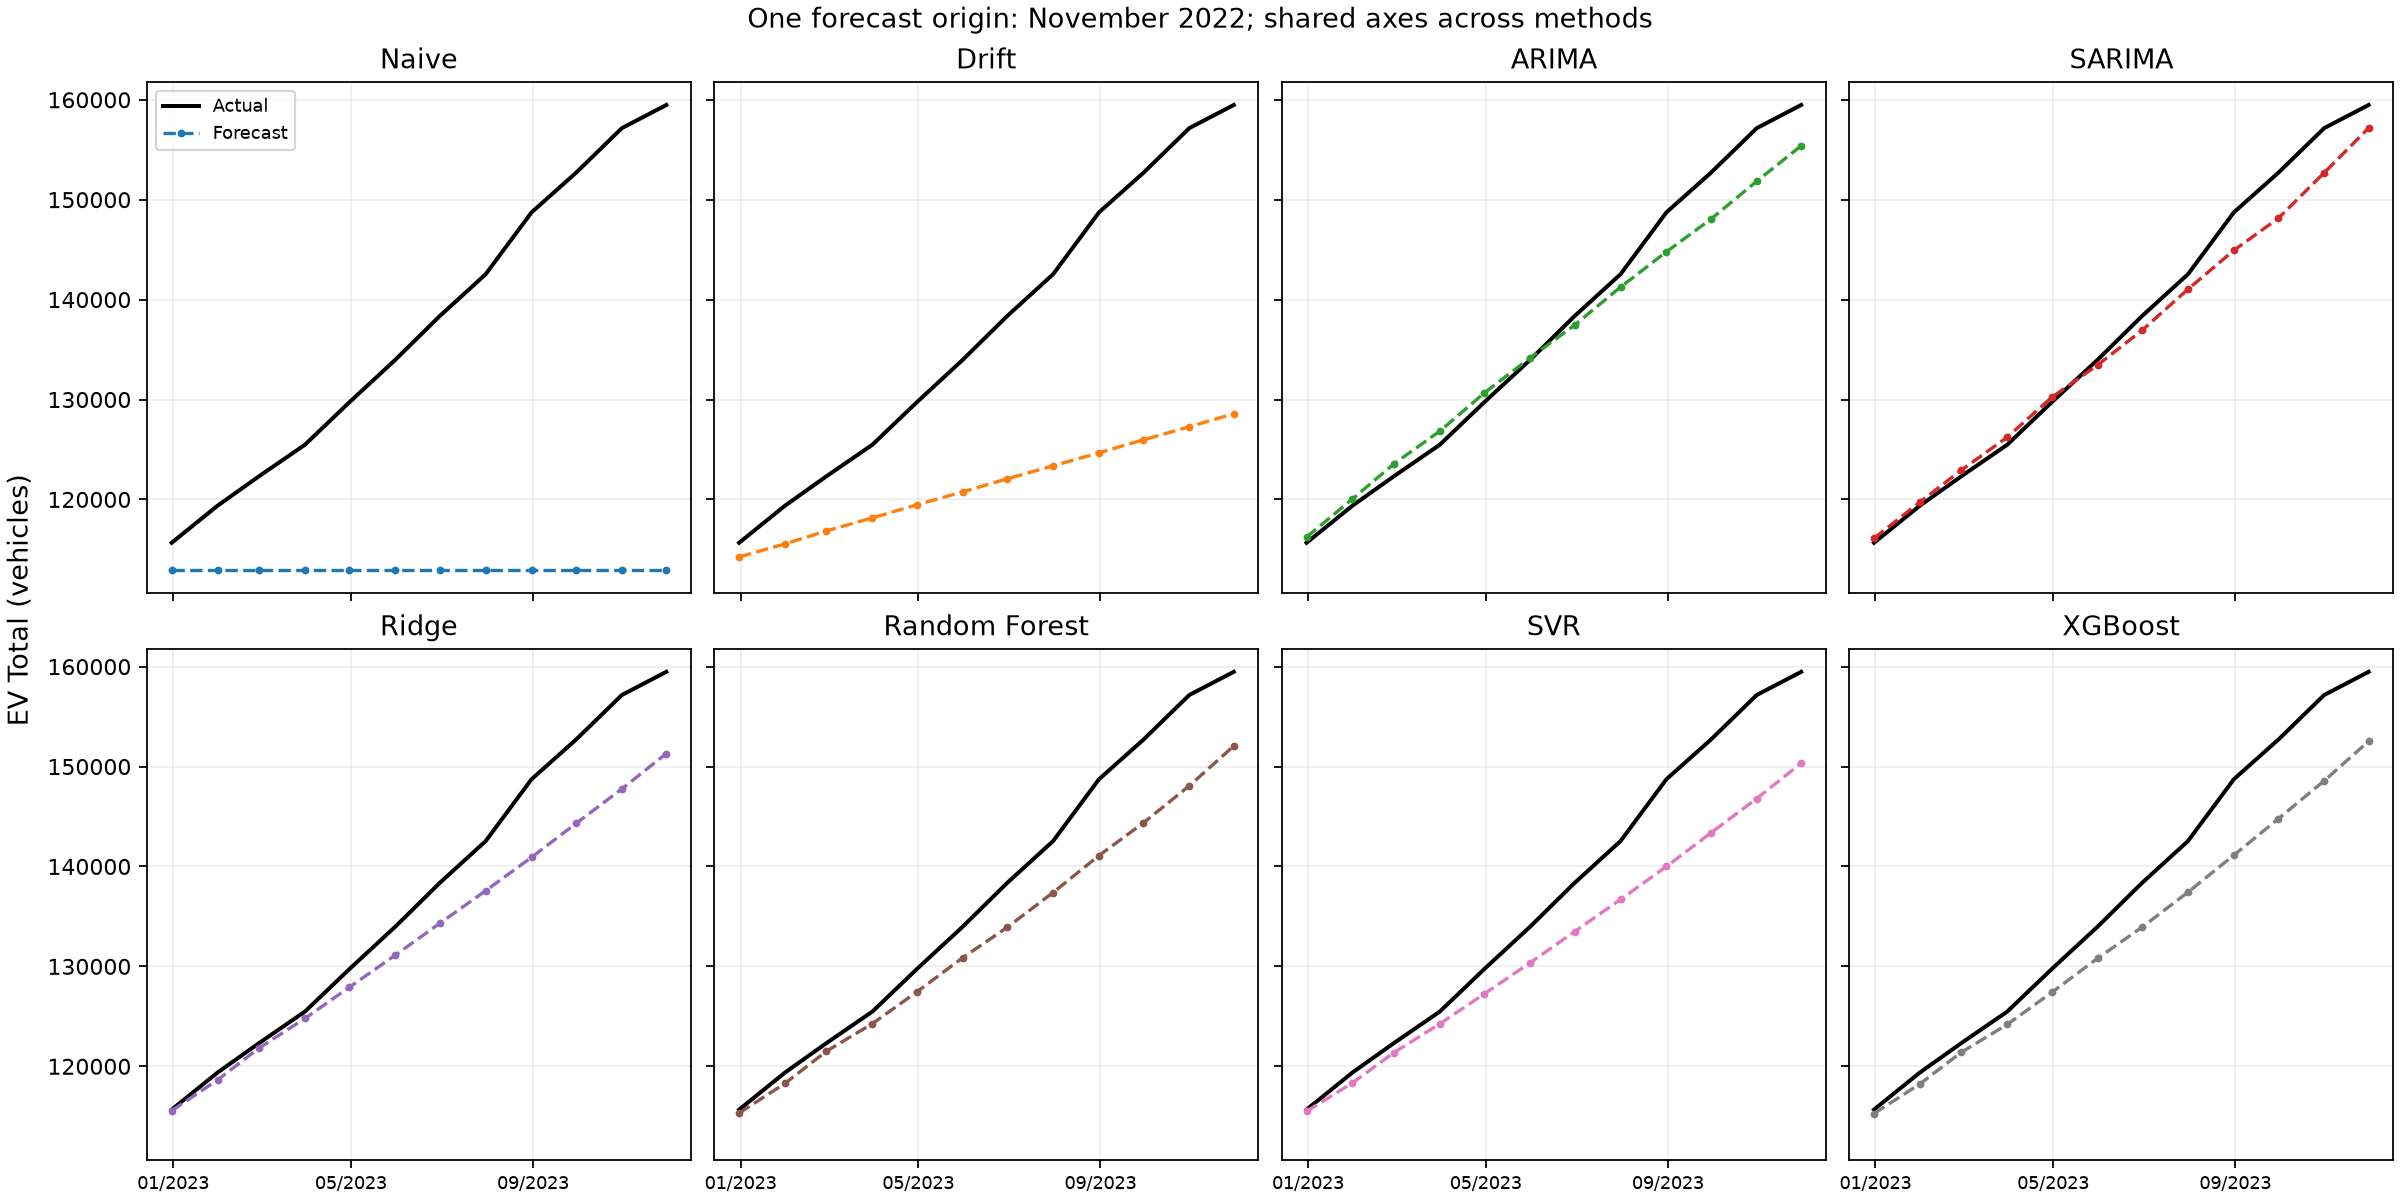

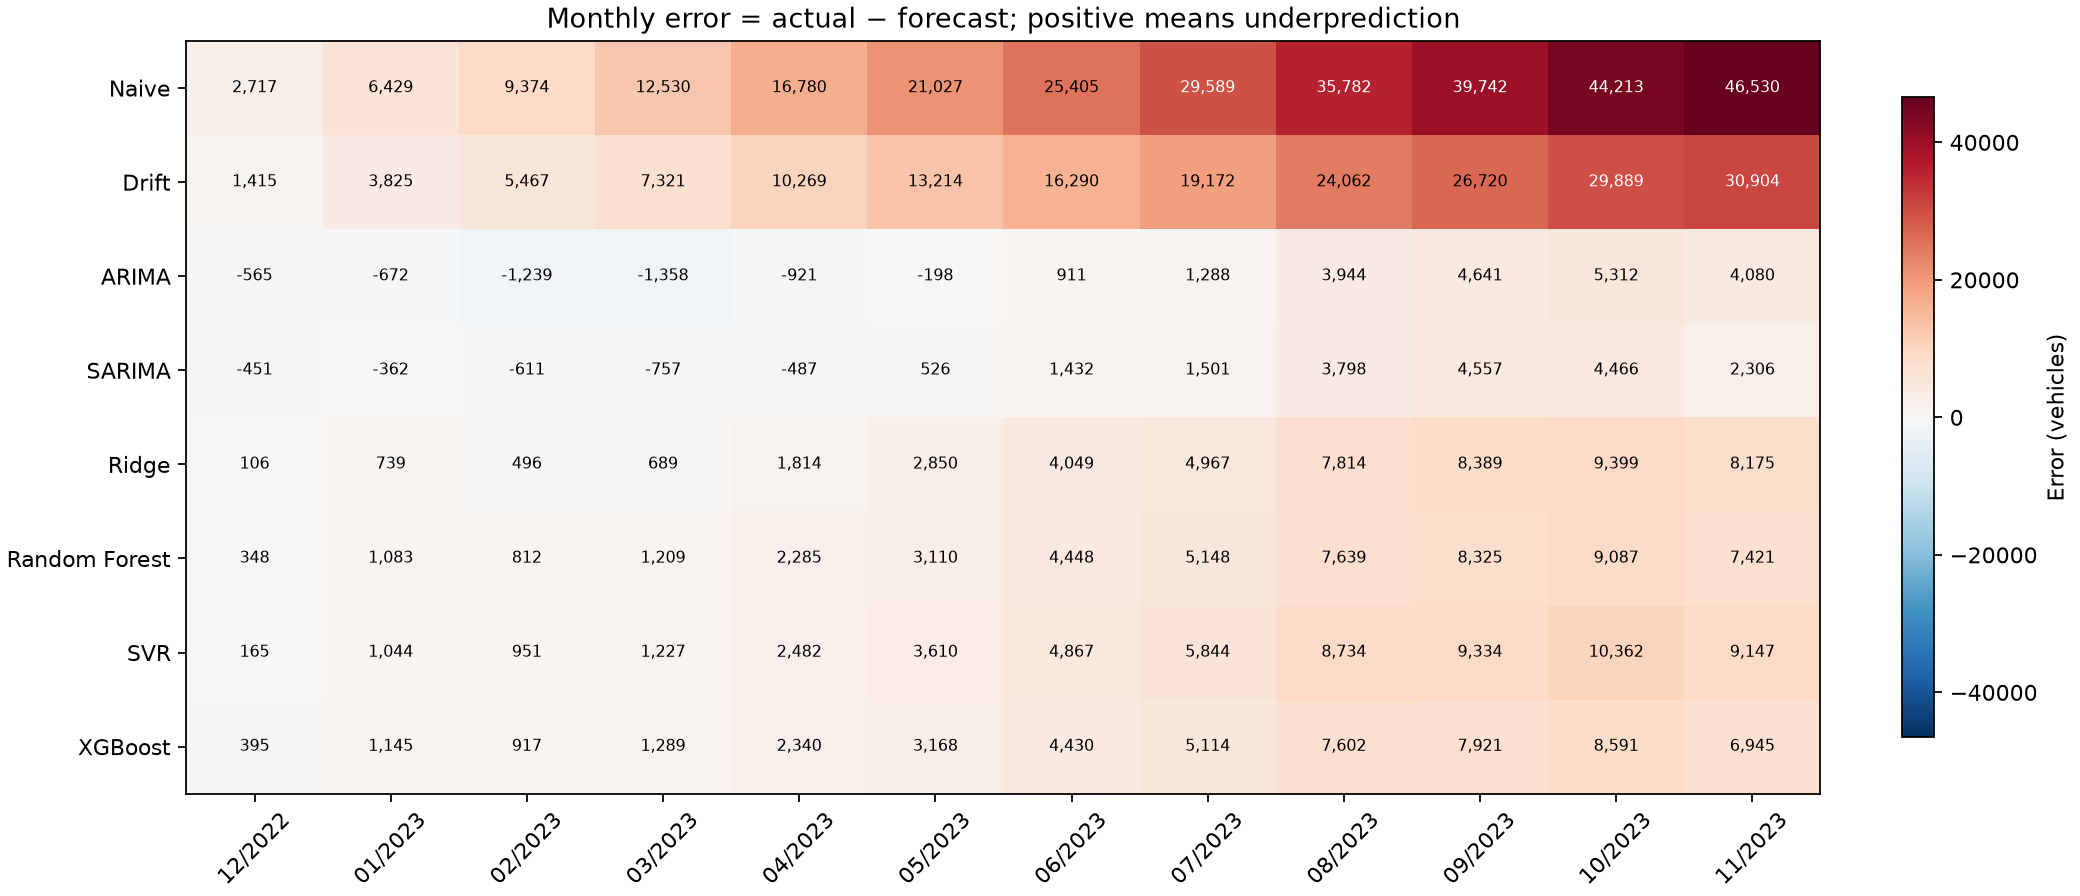

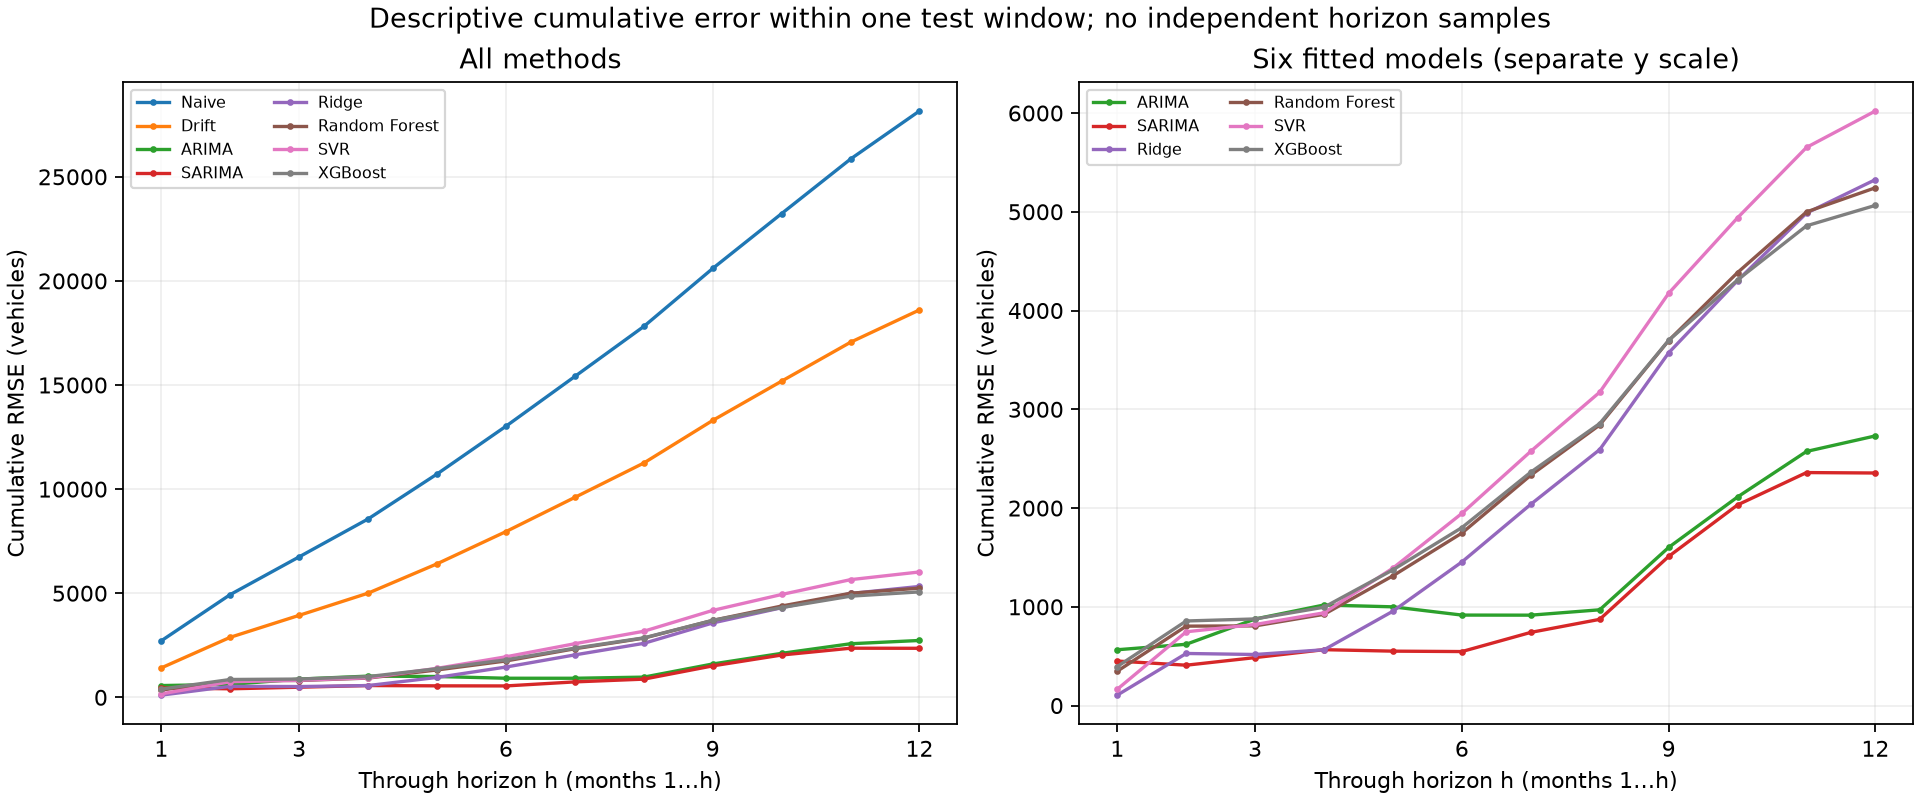

In [10]:
figures = OUT/'figures'
figures.mkdir()
draw(tables,figures)
for name in FIGURES: show_png(figures/name)


## Đối chiếu bảng và xuất demo
Không ghi đè bảng so sánh chính thức. Đây là so sánh trong cửa sổ 12/2022–11/2023, không tuyên bố vượt trội về thống kê.

In [11]:
for name,frame in tables.items():
    reference = pd.read_csv(forecast_dir/name)
    from io import StringIO
    # So đúng nội dung xuất CSV, thống nhất ô trống của nullable integer/boolean.
    csv_view = pd.read_csv(StringIO(frame.to_csv(index=False)))
    pd.testing.assert_frame_equal(csv_view,reference,check_dtype=False)
    save_table(frame,OUT/name)
print('Sáu bảng so sánh khớp kết quả đã lưu; output:',OUT)


Sáu bảng so sánh khớp kết quả đã lưu; output: D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\notebook_demo\forecast_comparison_20261116_041208_02215e19
